# Project 33: Automated ETL Excel Log → SQL Database

Semua tabel dibaca dari `results/` (hasil skrip ETL, SQL, dan Python). Data adalah simulasi buatan sendiri (60 file Excel, 3 versi template, Mar–Agu 2026).

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next(ROOT / 'results' / d / f for d in ('1-data-preparation', '2-analysis', '3-presentation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})

## Inventaris template
Tiga versi template berbeda baris judul, header, sel gabungan, baris kosong, dan baris total.

In [2]:
R('template_inventory.csv')

,template_version,files,data_rows,blank_rows,summary_rows,title_rows,merged_cells,header_row
0,v1,20,2420,0,0,80,0,5
1,v2,20,2420,80,0,40,20,3
2,v3,20,2420,0,20,0,0,1


## Hasil run ETL
Run kedua memuat 0 baris baru (idempotent).

In [3]:
R('etl_runs_summary.csv')

,run_id,files_read,rows_read,rows_skipped,rows_valid,rows_inserted,rows_rejected,duration_s,load_rate,reject_rate
0,1,60,7260,100,6960,6960,300,1.3000,0.9587,0.0413
1,2,60,7260,100,6960,0,300,1.1000,0.9587,0.0413


## Jenis masalah dan perlakuannya

In [4]:
R('issues_by_type.csv')

,kode,jenis,perlakuan,baris,pct_baris
0,R04,OK + NG tidak sama dengan input,Dikarantina,180,0.0248
1,R01,Kolom wajib kosong atau tidak terbaca,Dikarantina,60,0.0083
2,R03,Jumlah negatif,Dikarantina,60,0.0083
3,R05,"Baris ganda (kunci tanggal, stasiun, model, sh...",Dikarantina,60,0.0083
4,model_dinormalkan,Penulisan model tidak seragam,"Diperbaiki format, dimuat",60,0.0083
5,satuan_angka_dibuang,Angka bersatuan teks (mis. 480 pcs),"Diperbaiki format, dimuat",60,0.0083


In [5]:
R('issue_recovery.csv')

,jenis_masalah,ditanam,ditangani_benar,tindakan_diharapkan,pct
0,model_typo,60,60,dimuat dengan nilai benar,1.0000
1,text_qty,60,60,dimuat dengan nilai benar,1.0000
2,blank_cell,60,60,dikarantina R01,1.0000
3,negative_qty,60,60,dikarantina R03,1.0000
4,ok_ng_mismatch,60,60,dikarantina R04,1.0000
5,formula_overwrite,60,60,dikarantina R04,1.0000
6,duplicate_row,60,60,"baris asli dimuat, salinan dikarantina R05",1.0000
7,baris tanpa masalah (positif palsu),6780,6780,dimuat dengan nilai sama persis dengan data be...,1.0000


## Kualitas data per stasiun dan bulan

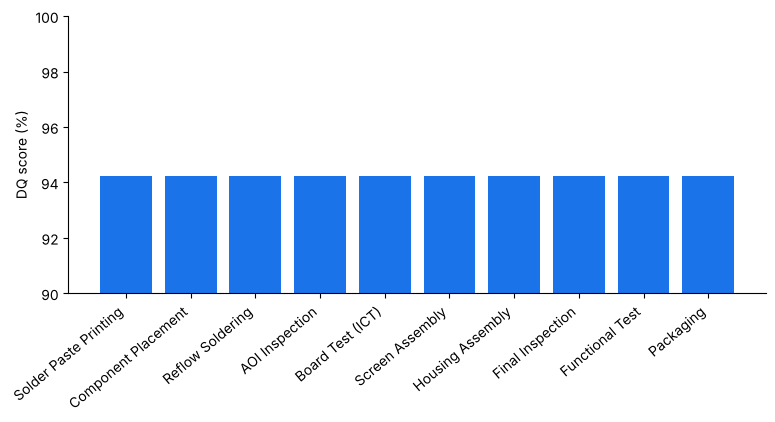

In [6]:
d = R('dq_station.csv'); plt.bar(d.station, d.dq_score, color='#1A73E8'); plt.xticks(rotation=40, ha='right'); plt.ylim(90, 100); plt.ylabel('DQ score (%)'); plt.show()

In [7]:
R('dq_month.csv')

,month,template_version,rows_total,rows_clean,rows_fixed,rows_rejected,dq_score,reject_rate
0,2026-03,v1,1210,1140,20,50,94.2149,0.0413
1,2026-04,v1,1210,1140,20,50,94.2149,0.0413
2,2026-05,v2,1210,1140,20,50,94.2149,0.0413
3,2026-06,v2,1210,1140,20,50,94.2149,0.0413
4,2026-07,v3,1210,1140,20,50,94.2149,0.0413
5,2026-08,v3,1210,1140,20,50,94.2149,0.0413


## Produksi per stasiun dan tren harian

In [8]:
R('prod_station.csv')

,station,ord,input_qty,ok_qty,ng_qty,yield
0,Solder Paste Printing,1,287734,284143,3591,0.9875
1,Component Placement,2,287625,284361,3264,0.9887
2,Reflow Soldering,3,287355,275205,12150,0.9577
3,AOI Inspection,4,287888,285519,2369,0.9918
4,Board Test (ICT),5,287561,283729,3832,0.9867
5,Screen Assembly,6,287157,284193,2964,0.9897
6,Housing Assembly,7,287236,282817,4419,0.9846
7,Final Inspection,8,287476,283874,3602,0.9875
8,Functional Test,9,288244,282326,5918,0.9795
9,Packaging,10,287748,286830,918,0.9968


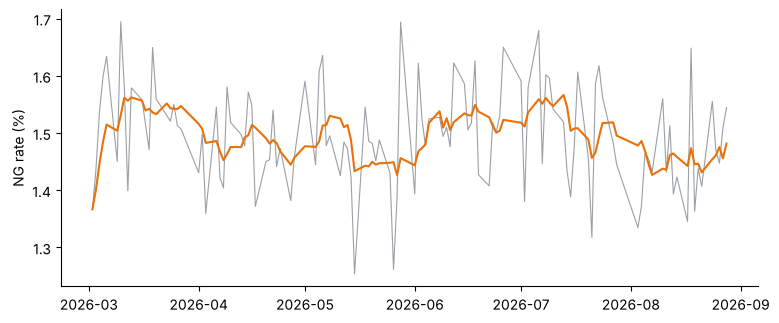

,station,date,input_qty,ng_qty,ng_rate,mean_ng_rate,sd_ng_rate,z
0,Packaging,2026-07-09,2465,19,0.0077,0.0032,0.0011,4.1617
1,Functional Test,2026-03-06,2429,73,0.0301,0.0205,0.0030,3.1945
2,Component Placement,2026-07-02,2391,44,0.0184,0.0113,0.0023,3.1064


In [9]:
t = R('daily_trend.csv'); x = pd.to_datetime(t.date); plt.plot(x, t.ng_rate * 100, color='#9AA0A6', lw=.8); plt.plot(x, t.ng_rate_ma7 * 100, color='#E8710A'); plt.ylabel('NG rate (%)'); plt.show(); R('daily_spikes.csv')

## Cek silang dan rekonsiliasi

In [10]:
a, b, c = R('crosscheck.csv'), R('reconciliation.csv'), R('reconciliation_excel.csv')
print(f'pandas: {(a.status == "PASS").sum()}/{len(a)} PASS; rekonsiliasi file: {(b.status == "PASS").sum()}/{len(b)} PASS; Excel: {(c.status == "PASS").sum()}/{len(c)} PASS')
R('total_row_check.csv')

pandas: 10/10 PASS; rekonsiliasi file: 60/60 PASS; Excel: 241/241 PASS


,source_file,total_row,input_rows_in_file,selisih
0,log_01_solder_2026-07.xlsx,49601,50039,438
1,log_01_solder_2026-08.xlsx,50244,50738,494
2,log_02_component_2026-07.xlsx,49171,49611,440
3,log_02_component_2026-08.xlsx,49699,50146,447
4,log_03_reflow_2026-07.xlsx,49670,50095,425
5,log_03_reflow_2026-08.xlsx,49686,50059,373
6,log_04_aoi_2026-07.xlsx,50099,50473,374
7,log_04_aoi_2026-08.xlsx,50015,50447,432
8,log_05_board_2026-07.xlsx,49069,49498,429
9,log_05_board_2026-08.xlsx,49872,50271,399


## Uji run ulang

In [11]:
R('rerun_test.csv')

,test,expected,actual,status
0,A. Run ke-3: baris baru masuk production_log,0,0,PASS
1,A. Run ke-3: isi tabel stg_raw_rows (jumlah da...,"(7260, '7d2dd25ea1074886bd8541f509ce84a1')","(7260, '7d2dd25ea1074886bd8541f509ce84a1')",PASS
2,A. Run ke-3: isi tabel rejected_rows (jumlah d...,"(360, 'e38b7b6ee5b0284ac68c49a8c66697bd')","(360, 'e38b7b6ee5b0284ac68c49a8c66697bd')",PASS
3,A. Run ke-3: isi tabel production_log (jumlah ...,"(6960, '8892f1812ac36cd32525eb884a6fcf12')","(6960, '8892f1812ac36cd32525eb884a6fcf12')",PASS
4,A. Run ke-3: baris etl_run_log bertambah satu,3,3,PASS
5,B. 100 baris dihapus: production_log berkurang,6860,6860,PASS
6,B. Run ulang memulihkan tepat 100 baris,100,100,PASS
7,B. Isi production_log kembali sama (kecuali no...,"(6960, '8892f1812ac36cd32525eb884a6fcf12')","(6960, '8892f1812ac36cd32525eb884a6fcf12')",PASS
8,C. Baris karantina yang bisa diperbaiki (bukan...,240,240,PASS
9,"C. Salinan baris ganda (dibuang, tidak diperba...",60,60,PASS


## Dampak waktu (estimated / simulated)

In [12]:
display(R('impact_steps.csv')); display(R('impact.csv')); R('wait_time.csv')

,langkah,menit_manual,menit_setelah_etl,menit_dihemat
0,Kumpulkan file,25,1,24
1,Salin dan gabung,40,0,40
2,Rapikan format,35,0,35
3,Cek salah ketik,30,5,25
4,Hitung KPI,20,0,20
5,Buat grafik,20,2,18


,laporan_per_bulan,laporan_per_tahun,menit_manual,menit_etl,jam_dihemat_per_tahun,dipakai
0,4,48,170.0000,8.0200,129.6000,tidak
1,8,96,170.0000,8.0200,259.2000,ya
2,12,144,170.0000,8.0200,388.7000,tidak


,kondisi,jam,pengurangan
0,Manual (asumsi),24.0000,0.0000
1,Setelah ETL (asumsi + durasi run terukur),0.2504,0.9896


## Validasi: fakta yang ditanam generator

In [13]:
R('ground_truth_check.csv')[['fact_no', 'fakta', 'ditemukan', 'hasil']]

,fact_no,fakta,ditemukan,hasil
0,1,"Tiga versi template, termasuk satu template kh...","3 versi template ditemukan (v1 20 file, v2 20 ...",Sebagian
1,2,"Format tanggal campuran: 02/08/2026, 2026-08-0...","5 format tanggal ditemukan (datetime: 2420, dd...",Sebagian
2,3,"Nama model beragam: Pro, PRO, pro, dan Model Pro","60 baris bernama model tidak baku ('PRO.', 'ba...",Sebagian
3,4,"Merged cell di judul, baris subtotal, dan bari...","20 file dengan merged cell, 20 baris TOTAL, 80...",Sesuai
4,5,Sekitar 2 sampai 3% nilai tidak valid; NG Refl...,"420 masalah tertanam (5.8% baris), 300 perlu k...",Sebagian
